# Data import

In [230]:
# Dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from data_engineering import make_splits, load_raw, clean, build_features

In [231]:
# Load data
raw_data = load_raw()
df = clean(raw_data)
out = make_splits(df)

In [232]:
data = []
for ts, (X_tr, X_te, y_tr, y_te, info) in out.items():
        data.append((ts, X_tr, X_te, y_tr, y_te, info))
        print(f"test={ts:.0%} -> train {X_tr.shape}, test {X_te.shape}, "
              f"%>50K train={y_tr.mean():.3f} test={y_te.mean():.3f}")

test=10% -> train (43911, 88), test (4879, 88), %>50K train=0.239 test=0.239
test=20% -> train (39032, 88), test (9758, 88), %>50K train=0.239 test=0.239
test=30% -> train (34153, 88), test (14637, 88), %>50K train=0.239 test=0.239
test=40% -> train (29274, 88), test (19516, 88), %>50K train=0.239 test=0.239


s, X_tr, X_te, y_tr, y_te, info
0, 1,    2,    3,    4,    5

# Perceptron

In [233]:
# Activation function Step
def g(z):
    if z >= 0:
        return 1
    else:
        return 0

In [234]:
def run(inputs, ws, bias):
    # We can see that the forward run of the perceptron is just a dot product. Numpy does it pretty well
    z = np.dot(inputs, ws) + bias
    return g(z)


In [235]:
def update(inputs, ws, bias, e, alpha=0.05):
    ws = ws + alpha * e * inputs
    bias = bias + alpha * e
    return ws, bias

In [236]:
def train(df, alpha,epochs):
    inputs = df[1].to_numpy()[:, :4] # Use only the first 4 features
    targets = df[3].to_numpy()
    ws = np.random.rand(inputs.shape[1])
    bias = 0.0
    history = []
    for epoch in range(epochs):
        mistakes = 0
        for i in range(len(inputs)):
            y_hat = run(inputs[i], ws, bias)
            e = targets[i] - y_hat
            if e != 0:
                mistakes += 1
                ws, bias = update(inputs[i], ws, bias, e, alpha)
        history.append(mistakes)
        #print(f"Epoch {epoch+1}/{epochs} -> Mistakes: {mistakes}")
    return ws, bias, history

In [246]:
ws, bias, history = train(data[0], 0.001, 200)

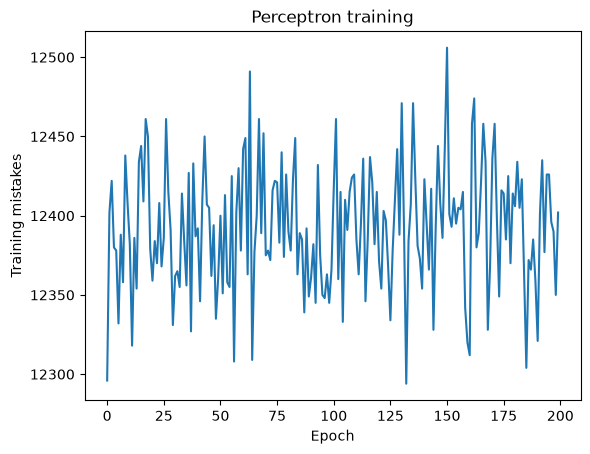

In [242]:
plt.plot(history)
plt.xlabel("Epoch")
plt.ylabel("Training mistakes")
plt.title("Perceptron training")
plt.show()

# Test the model

In [247]:
def test(df, ws, bias):
    inputs = df[2].to_numpy()[:, :4] # Use only the first 4 features
    targets = df[4].to_numpy()
    mistakes = 0
    for i in range(len(inputs)):
        y_hat = run(inputs[i], ws, bias)
        e = targets[i] - y_hat
        if e != 0:
            mistakes += 1
    return mistakes

In [248]:
erors = test(data[0], ws, bias)
error_rate = erors / len(data[0][2])
print(f"Test error rate: {error_rate:.3f}")

Test error rate: 0.306


# Compare with diferent data sizes

In [259]:
def run_perceptron(i, alpha, epochs):
    print(f"Running perceptron for test={i+1} with alpha={alpha} and epochs={epochs}")
    ws, bias, history = train(data[i], alpha, epochs)
    plt.plot(history)
    plt.xlabel("Epoch")
    plt.ylabel("Training mistakes")
    plt.title(f"Perceptron training (test={i:.0%})")
    plt.show()
    errors = test(data[i], ws, bias)
    error_rate = errors / len(data[i][2])
    print(f"Test error rate: {error_rate:.3f}")

Running perceptron for test=1 with alpha=0.001 and epochs=200


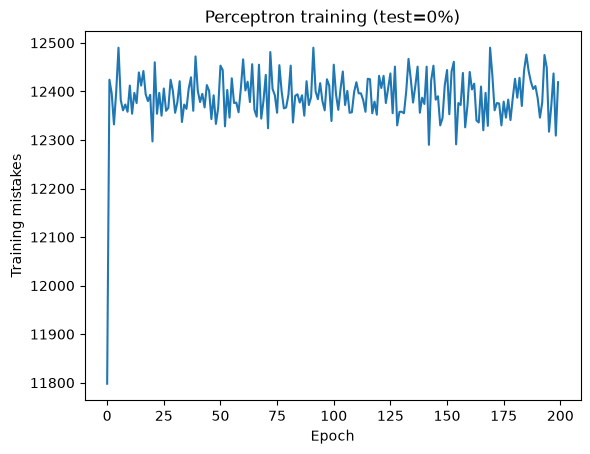

Test error rate: 0.285
Running perceptron for test=2 with alpha=0.001 and epochs=200


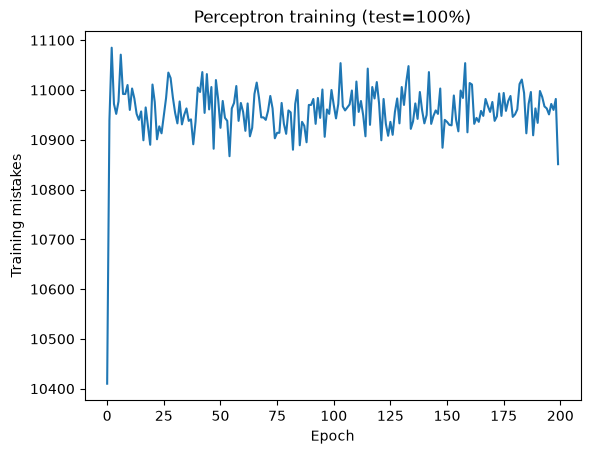

Test error rate: 0.296
Running perceptron for test=3 with alpha=0.001 and epochs=200


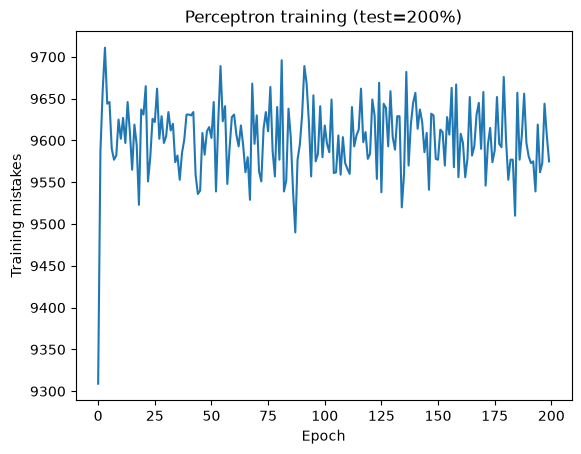

Test error rate: 0.311
Running perceptron for test=4 with alpha=0.001 and epochs=200


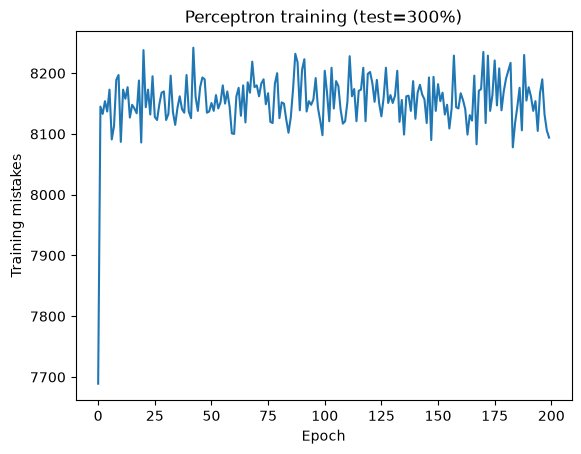

Test error rate: 0.310


In [260]:
for i in range(len(data)):
    run_perceptron(i, 0.001, 200) 